<a href="https://colab.research.google.com/github/RobertoSonzini/NAML_project/blob/LSMT_implementation/LSTM_implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import jax
import jax.numpy as jnp
from jax import grad, jit, vmap, lax
from jax import random

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
import torch
from torch import nn
import math
from sklearn.preprocessing import MinMaxScaler

In [3]:
print(jax.devices())

[CudaDevice(id=0)]


In [4]:
file_path = '/content/drive/MyDrive/ProgettoNAML/all_stocks_5yr.csv'
drive.mount('/content/drive')

df = pd.read_csv(file_path)
df.head()

%matplotlib inline

from datetime import datetime

df.info()
df

Mounted at /content/drive
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619040 entries, 0 to 619039
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    619040 non-null  object 
 1   open    619029 non-null  float64
 2   high    619032 non-null  float64
 3   low     619032 non-null  float64
 4   close   619040 non-null  float64
 5   volume  619040 non-null  int64  
 6   Name    619040 non-null  object 
dtypes: float64(4), int64(1), object(2)
memory usage: 33.1+ MB


,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL
...,...,...,...,...,...,...,...
619035,2018-02-01,76.84,78.27,76.69,77.82,2982259,ZTS
619036,2018-02-02,77.53,78.12,76.73,76.78,2595187,ZTS
619037,2018-02-05,76.64,76.92,73.18,73.83,2962031,ZTS
619038,2018-02-06,72.74,74.56,72.13,73.27,4924323,ZTS


In [5]:
def sort_by_date(df):
  return df.sort_values(by='date')

In [6]:
def get_dataframe(df, company_names, moving_average=5):
    input_data_labels = ['high', 'low', 'open', 'volume', 'ma5']
    close_data = ['close']

    mask = df['Name'].isin(company_names)
    df_company = df.loc[mask].copy()

    df_company['ma5'] = df_company['close'].rolling(moving_average).mean()

    df_company = df_company.dropna()

    df_company = sort_by_date(df_company)

    return df_company[input_data_labels], df_company[close_data]

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# prendo nuovamente i dati

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

In [8]:
from torch.utils.data import Dataset

class MyDataset(Dataset):
    def __init__(self, X_data, y_data, seq_len = 1):
      self.X_data = X_data  # array, tensor o lista di feature
      self.y_data = y_data  # target (opzionale se inferenza)
      self.seq_len = seq_len

    def __len__(self):
      return len(self.y_data) - self.seq_len

    def __getitem__(self, idx):
      x = self.X_data[idx : idx + self.seq_len]
      y = self.y_data[idx + self.seq_len] # il target qui lo prendo solo sul passo successivo (last step)

      # x_tensor = torch.tensor(x)
      # y_tensor = torch.tensor(y)

      return x, y

In [9]:
# per esempio di utilizzo

from torch.utils.data import DataLoader

dataset = MyDataset(X_train, y_train, seq_len = 10)
loader = DataLoader(dataset, batch_size=32, shuffle=False)

In [10]:
def mse_loss(y_pred, y_true):
    return jnp.mean((y_pred - y_true) ** 2)

In [11]:
def sigmoid(x):
    return 1.0 / (1.0 + jnp.exp(-x))

def dsigmoid_from_output(s):
    # s = sigmoid(x)
    return s * (1 - s)

def dtanh_from_output(t):
    # t = tanh(x)
    return 1 - t ** 2

# **Implementazione jit-friendly**

In [12]:
import jax
import jax.numpy as jnp
from jax import jit, vmap, lax, grad
from jax.nn import sigmoid

# ---------- FUNZIONI PURE ----------
def forward_step(params, x_t, h_prev, s_prev):
    i_t = sigmoid(params['U_i'] @ x_t + params['W_i'] @ h_prev + params['b_i'])
    f_t = sigmoid(params['U_f'] @ x_t + params['W_f'] @ h_prev + params['b_f'])
    g_t = jnp.tanh(params['U_g'] @ x_t + params['W_g'] @ h_prev + params['b_g'])
    o_t = sigmoid(params['U_o'] @ x_t + params['W_o'] @ h_prev + params['b_o'])

    s_t = f_t * s_prev + i_t * g_t
    h_t = o_t * jnp.tanh(s_t)

    y_t = params['V'] @ h_t + params['b_out']
    return h_t, s_t, y_t

def forward(params, X, hidden_size):
    h0 = jnp.zeros((hidden_size,))
    s0 = jnp.zeros((hidden_size,))

    def step_scan(carry, x_t):
        h_prev, s_prev = carry
        h_t, s_t, y_t = forward_step(params, x_t, h_prev, s_prev)
        return (h_t, s_t), y_t

    (h_final, s_final), Y_seq = lax.scan(step_scan, (h0, s0), X)
    return Y_seq[-1]  # (output_size,)

def forward_batch(params, X_batch, hidden_size):
    return vmap(lambda X_seq: forward(params, X_seq, hidden_size))(X_batch)

def loss(params, X, Y_true, hidden_size, loss_fn):
    Y_pred = forward(params, X, hidden_size)
    return loss_fn(Y_pred, Y_true)

def backward_batch(params, X_batch, Y_batch, hidden_size, lr, loss_fn):
    def batch_loss(p):
        return jnp.mean(vmap(lambda X_seq, Y_seq: loss(p, X_seq, Y_seq, hidden_size, loss_fn))
                        (X_batch, Y_batch))
    grads = grad(batch_loss)(params)
    new_params = {k: params[k] - lr * grads[k] for k in params.keys()}
    return new_params

# ---------- VERSIONI JITTATE ----------
forward_jit = jax.jit(forward, static_argnames=['hidden_size'])
forward_batch_jit = jax.jit(forward_batch, static_argnames=['hidden_size'])
loss_jit = jax.jit(loss, static_argnames=['hidden_size'])
backward_batch_jit = jax.jit(backward_batch, static_argnames=['hidden_size'])


# ---------- WRAPPER ----------
class LSTM_wrapper:
    def __init__(self, key, input_size, hidden_size, output_size, loss_function):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.loss_function = loss_function
        self.key = key

        # Split the key for different initializations
        keys = jax.random.split(self.key, 9)

        # Inizializzazione pesi
        self.params = {
            'U_f': jax.random.uniform(keys[0], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_f': jax.random.uniform(keys[1], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_f': jnp.ones((hidden_size,)),

            'U_i': jax.random.uniform(keys[2], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_i': jax.random.uniform(keys[3], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_i': jnp.zeros((hidden_size,)),

            'U_g': jax.random.uniform(keys[4], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_g': jax.random.uniform(keys[5], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_g': jnp.zeros((hidden_size,)),

            'U_o': jax.random.uniform(keys[6], (hidden_size, input_size), minval=-0.1, maxval=0.1),
            'W_o': jax.random.uniform(keys[7], (hidden_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_o': jnp.zeros((hidden_size,)),

            'V': jax.random.uniform(keys[8], (output_size, hidden_size), minval=-0.1, maxval=0.1),
            'b_out': jnp.zeros((output_size,)),
        }

    # ---- Metodi wrapper ----
    def forward_batch(self, params, X_batch):
        return forward_batch_jit(params, X_batch, self.hidden_size)

    def loss(self, params, X, Y_true):
        return loss_jit(params, X, Y_true, self.hidden_size, self.loss_function)

    def backward_batch(self, params, X_batch, Y_batch, lr=0.01):
        return backward_batch_jit(params, X_batch, Y_batch, self.hidden_size, lr, self.loss_function)


In [13]:
# hyperparameters
input_size = 5
# hidden size = 48
hidden_size = 48
num_epochs = 500
# lr = 0.055
# seq_len = 5
lr = 0.055
seq_len = 5
output_size = 1

key = random.PRNGKey(0)
model = LSTM_wrapper(key, input_size, hidden_size, output_size, loss_function=mse_loss)

In [14]:
from datetime import datetime
import jax
import jax.numpy as jnp
from jax import jit, grad

# ---------- TRAIN STEP JITTATO ----------
def train_step(params, X_batch, Y_batch, lr, model):
    """
    Esegue un passo di training su un batch jittato.
    """
    def batch_loss(p):
        Y_pred = model.forward_batch(p, X_batch)
        return jnp.mean((Y_pred - Y_batch) ** 2)  # MSE, puoi sostituire con loss personalizzata

    grads = grad(batch_loss)(params)
    new_params = jax.tree_map(lambda p, g: p - lr * g, params, grads)
    return new_params

train_step_jit = jax.jit(train_step, static_argnames='model')

# ---------- TRAIN LOOP ----------
def train_LSTM(model, X_train, y_train, seq_len, batch_size=32, learning_rate=0.001, epochs=500):
    """
    Training loop per la LSTM con batch jittato.
    X_train: array (num_samples, seq_len, input_size)
    y_train: array (num_samples, seq_len, output_size)
    """
    # Crea dataset e loader
    dataset = MyDataset(X_train, y_train, seq_len=seq_len)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    losses = []

    for epoch in range(epochs):
        epoch_loss = 0.0

        for samples, labels in loader:
            # Converti batch in JAX arrays
            X_batch = jnp.array(samples, dtype=jnp.float32)
            Y_batch = jnp.array(labels, dtype=jnp.float32)

            # Aggiorna parametri con train_step jittato
            model.params = train_step_jit(model.params, X_batch, Y_batch, learning_rate, model)

            # Loss del batch per monitoraggio
            Y_pred = model.forward_batch(model.params, X_batch)
            batch_loss = jnp.mean((Y_pred - Y_batch) ** 2)
            epoch_loss += batch_loss

        avg_loss = epoch_loss / len(loader)
        losses.append(avg_loss)

        if (epoch+1) % 50 == 0:
            print(f'Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.6f} [{datetime.now()}]')

    return losses


In [15]:
losses = train_LSTM(model, X_train, y_train, seq_len=seq_len, learning_rate=lr, epochs=num_epochs)

/tmp/ipython-input-1247185900.py:16: DeprecationWarning: jax.tree_map is deprecated: use jax.tree.map (jax v0.4.25 or newer) or jax.tree_util.tree_map (any JAX version).
  new_params = jax.tree_map(lambda p, g: p - lr * g, params, grads)


Epoch [50/500], Loss: 0.005188 [2025-08-21 09:31:24.543490]
Epoch [100/500], Loss: 0.004399 [2025-08-21 09:31:30.971868]
Epoch [150/500], Loss: 0.003967 [2025-08-21 09:31:36.864513]
Epoch [200/500], Loss: 0.003650 [2025-08-21 09:31:42.898950]
Epoch [250/500], Loss: 0.003440 [2025-08-21 09:31:47.671704]
Epoch [300/500], Loss: 0.003399 [2025-08-21 09:31:52.592626]
Epoch [350/500], Loss: 0.003263 [2025-08-21 09:31:58.513136]
Epoch [400/500], Loss: 0.003267 [2025-08-21 09:32:03.305379]
Epoch [450/500], Loss: 0.003291 [2025-08-21 09:32:09.484733]
Epoch [500/500], Loss: 0.003160 [2025-08-21 09:32:14.220700]


In [16]:
def test_LSTM(model, X_test, y_test, seq_len, loss_function, batch_size=32):
    total_loss = 0
    preds = []
    actuals = []

    dataset = MyDataset(X_test, y_test, seq_len=seq_len)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    for x_batch, y_batch in loader:
        X_batch = jnp.array(x_batch, dtype=jnp.float32)
        Y_batch = jnp.array(y_batch, dtype=jnp.float32)

        Y_pred = model.forward_batch(model.params, X_batch)

        loss = jnp.mean((Y_pred - Y_batch)**2)
        total_loss += loss * X_batch.shape[0]

        preds.extend(np.array(Y_pred))
        actuals.extend(np.array(Y_batch))

    avg_loss = total_loss / len(loader.dataset)
    print(f"Test Loss: {avg_loss:.4f}")

    return preds, actuals

In [17]:
preds, actuals = test_LSTM(model, X_test, y_test, seq_len=seq_len, loss_function=mse_loss)

Test Loss: 0.0068


In [18]:
def plot_predictions(preds, actuals):
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

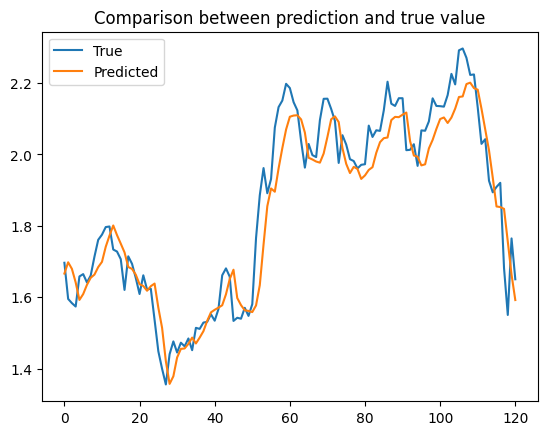

In [19]:
plot_predictions(preds, actuals)